# IMPORTS

In [ ]:
import os, sys, importlib, json, csv
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

# utils path
sys.path.append(os.path.abspath(os.path.join("..")))

# helper modules -  reload in case of edits
import utils.eda_helpers as eda_helpers
import utils.helpers as helpers
importlib.reload(eda_helpers)
importlib.reload(helpers)
from utils.eda_helpers import *
from pathlib import Path
sys.path.append(os.path.join(os.getcwd(), '..'))
from utils.helpers import convert_to_serializable, save_json, load_csv_data_streamed, load_csv_data
from utils.eda_helpers import clean_data  # Henrik's cleaning function

# data folder
file_path = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
DATA_FOLDER = os.path.join(file_path, '..', 'dataset')

# random seed
np.random.seed(42)

In [5]:
BASE_DIR = Path.cwd().resolve().parent
PLOTS_DIR = BASE_DIR / "plots" / "eda"
RESULTS_DIR = BASE_DIR / "results" / "eda"

for path in [PLOTS_DIR, RESULTS_DIR]:
    path.mkdir(parents=True, exist_ok=True)

print(f"Plots directory: {PLOTS_DIR}")
print(f"Results directory: {RESULTS_DIR}")


Plots directory: C:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda
Results directory: C:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\results\eda


In [ ]:
def read_csv_numeric(path):
    # 1) read header for the name→index mapping
    with open(path, newline='', encoding='utf-8') as f:
        reader = csv.reader(f)
        header = next(reader)
    col_idx = {name: i for i, name in enumerate(header)}

    # 2) load the rest as a 2D float array (missing -> NaN)
    # reopen so the file pointer is at the top again
    data = np.genfromtxt(
        path,
        delimiter=",",
        skip_header=1,
        dtype=float,
        missing_values=["", "NA", "NaN"],
        filling_values=np.nan
    )
    # if the CSV has only one data row, genfromtxt returns 1D; force 2D
    if data.ndim == 1:
        data = data.reshape(1, -1)

    return col_idx, data

In [7]:
x_indices, x_data = read_csv_numeric("../dataset/x_train.csv")
y_indices, y_data = read_csv_numeric("../dataset/y_train.csv")

In [8]:
print(f"x_train shape: {x_data.shape}")
print(f"y_train shape: {y_data.shape}")
print(f"Example features: {list(x_indices)[:5]}")

x_train shape: (328135, 322)
y_train shape: (328135, 2)
Example features: ['Id', '_STATE', 'FMONTH', 'IDATE', 'IMONTH']


We clean the raw training data using a custom helper function (imported from our custom module `utils.eda_helpers`) that handles missing values, inconsistent entries, and invalid numeric encodings, as well as maps all features into a consistent unit system (e.g weight only in kilograms not pounts and kilograms, height in meters etc.) This ensures that all features are in a consistent numeric format before running the EDA.

In [10]:
del x_indices["Id"]
x_data_clean = clean_data(x_data, x_indices)
print("Cleaned data shape:", x_data_clean.shape)

Cleaned data shape: (328135, 322)


# 1. Basic EDA

In this section, we perform an initial exploratory analysis of the dataset.  
We start by inspecting its **size, memory usage, and data types**, followed by basic **feature-level descriptive statistics**.   We then analyze **missing values**, visualize their distribution across features, and explore key **distribution metrics** such as skewness and kurtosis to detect heavy-tailed or asymmetric features.  Finally, we examine the **target-variable distribution** to understand class balance before proceeding with deeper feature analysis.


In [11]:
x_train = x_data_clean
y_train = y_data[:, 1] if y_data.ndim > 1 else y_data
feature_names = list(x_indices.keys())
save_dir = RESULTS_DIR
plots_dir = PLOTS_DIR

### Size dataset

In [12]:
n, d = x_train.shape
print("Number of samples:", n)
print("Number of features:", d)
print("\ny distribution:", np.unique(y_train, return_counts=True))
print("Estimated memory (MB):", x_train.nbytes/1e6)
print("Data type:", x_train.dtype)

Number of samples: 328135
Number of features: 322

y distribution: (array([-1.,  1.]), array([299160,  28975]))
Estimated memory (MB): 845.27576
Data type: float64


### Features descriptive statistics

In [13]:
with open(os.path.join("..", "dataset", "x_train.csv"), "r") as f:
    reader = csv.reader(f)
    header = next(reader)  # first line = column names
feature_names = header[1:]  # exclude ID column
feature_names[:20]

['_STATE',
 'FMONTH',
 'IDATE',
 'IMONTH',
 'IDAY',
 'IYEAR',
 'DISPCODE',
 'SEQNO',
 '_PSU',
 'CTELENUM',
 'PVTRESD1',
 'COLGHOUS',
 'STATERES',
 'CELLFON3',
 'LADULT',
 'NUMADULT',
 'NUMMEN',
 'NUMWOMEN',
 'CTELNUM1',
 'CELLFON2']

In [ ]:
summary_extended = dataset_describe(
    x_data_clean,
    feature_names=list(x_indices.keys()),
    max_features=20
)


Dataset shape: 328,135 samples × 322 features
 Idx |            Name |       Type |  Unique |  Missing |  %Miss |         Mean |          Std |          Min |          Max
-----------------------------------------------------------------------------------------------------------------------------
   0 | _STATE          | continuous |  328135 |        0 |   0.00 |     1.64e+05 |     9.47e+04 |            0 |     3.28e+05
   1 | FMONTH          | continuous |      53 |        0 |   0.00 |           30 |           16 |            1 |           72
   2 | IDATE           | continuous |      12 |        0 |   0.00 |         6.36 |         3.49 |            1 |           12
   3 | IMONTH          | continuous |     414 |        0 |   0.00 |     6.56e+06 |     3.49e+06 |     1.01e+06 |     1.23e+07
   4 | IDAY            | continuous |      12 |        0 |   0.00 |         6.42 |         3.49 |            1 |           12
   5 | IYEAR           | continuous |      31 |        0 |   0.00 |    

In [20]:
# print extended summary
for f in summary_extended[:2]:
    print(f"\nFeature {f['index']}: {f['name']}")
    for k, v in f.items():
        if k not in ['index', 'name']:
            print(f"  {k}: {v}")


Feature 0: _STATE
  type: continuous
  n_unique: 328135
  missing: 0
  missing_pct: 0.0
  mean: 164067.0
  std: 94724.41528982905
  min: 0.0
  max: 328134.0

Feature 1: FMONTH
  type: continuous
  n_unique: 53
  missing: 0
  missing_pct: 0.0
  mean: 29.973651088728726
  std: 16.031752874847626
  min: 1.0
  max: 72.0


### Missing values

In [21]:
n = x_train.shape[0]
missing_per_feature = np.isnan(x_train).sum(axis=0)
missing_ratio = missing_per_feature / n * 100

In [22]:
# global summary ab missing values
missing_summary = {
    "total_missing": int(np.isnan(x_train).sum()),
    "mean_missing_pct": float(np.mean(missing_ratio)),
    "median_missing_pct": float(np.median(missing_ratio)),
    "max_missing_pct": float(np.max(missing_ratio)),
    "n_features_missing": int(np.sum(missing_per_feature > 0)),
}
save_json(missing_summary, "missing_summary", save_dir=save_dir)

Saved missing_summary.json to C:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\results\eda\missing_summary.json


In [23]:
# per-feature summary
missing_features_summary = [
    {"index": i, "name": feature_names[i], "missing_count": int(missing_per_feature[i]), "missing_pct": float(missing_ratio[i])}
    for i in range(len(feature_names))
]
save_json(missing_features_summary, "missing_features_summary", save_dir=save_dir)

Saved missing_features_summary.json to C:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\results\eda\missing_features_summary.json


In [24]:
# print
print(f"\nTotal missing values: {missing_summary['total_missing']:,}")
print(f"Average missing per feature: {missing_summary['mean_missing_pct']:.3f}%")
print(f"Features with any missing values: {missing_summary['n_features_missing']} / {len(feature_names)}")
print(f"Max missing percentage: {missing_summary['max_missing_pct']:.2f}% ({feature_names[np.argmax(missing_ratio)]})")


Total missing values: 48,736,658
Average missing per feature: 46.126%
Features with any missing values: 289 / 321
Max missing percentage: 99.99% (STATERES)


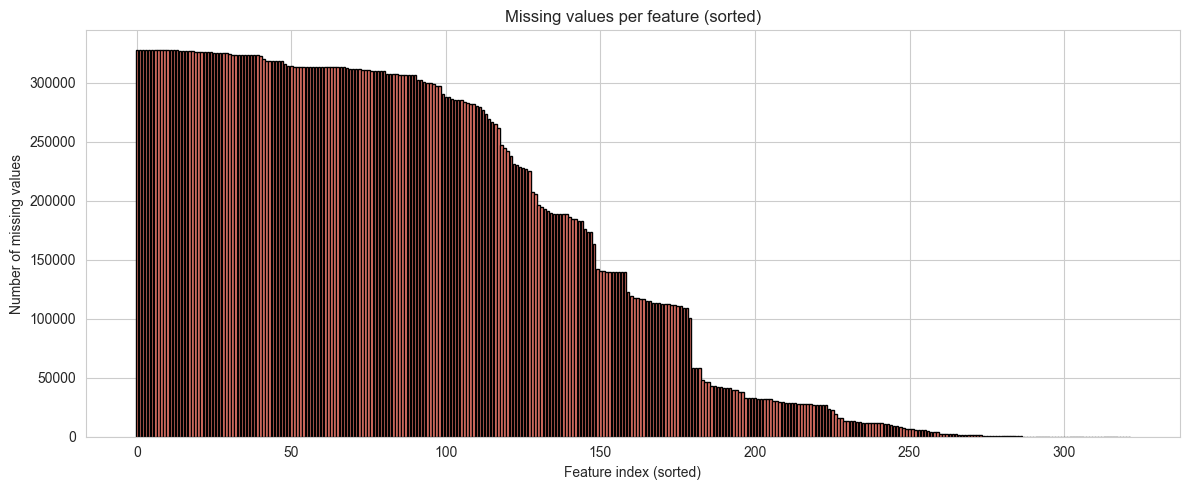

Saved sorted missing-values plot to C:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\missing_values_sorted.png


In [40]:
# === Missing values visualization (sorted descending, by index) ===
n_missing = np.sum(np.isnan(x_data_clean), axis=0)

# sort descending
sorted_idx = np.argsort(n_missing)[::-1]
sorted_missing = n_missing[sorted_idx]

plt.figure(figsize=(12, 5))
plt.bar(range(len(sorted_missing)), sorted_missing, color="salmon", edgecolor="black")
plt.xlabel("Feature index (sorted)")
plt.ylabel("Number of missing values")
plt.title("Missing values per feature (sorted)")
plt.tight_layout()

save_path = PLOTS_DIR / "missing_values_sorted.png"
plt.savefig(save_path, bbox_inches="tight")
plt.show()

print(f"Saved sorted missing-values plot to {save_path}")


### Feature distribution analysis

In [45]:
# basic distribution metrics 
means = np.nanmean(x_train, axis=0)
stds = np.nanstd(x_train, axis=0)

# manual skewness and kurtosis
def compute_skew(x):
    x = x[~np.isnan(x)]
    if len(x) < 3:
        return np.nan
    m = np.mean(x)
    s = np.std(x)
    if s == 0:
        return np.nan  # constant feature
    return np.mean(((x - m) / s) ** 3)

def compute_kurtosis(x):
    x = x[~np.isnan(x)]
    if len(x) < 4:
        return np.nan
    m = np.mean(x)
    s = np.std(x)
    if s == 0:
        return np.nan  # constant feature
    return np.mean(((x - m) / s) ** 4)


skews = np.array([compute_skew(x_train[:, i]) for i in range(x_train.shape[1])])
kurtoses = np.array([compute_kurtosis(x_train[:, i]) for i in range(x_train.shape[1])])

print(f"Average std across features: {np.nanmean(stds):.3f}")
print(f"Highly skewed features (|skew| > 2): {np.sum(np.abs(skews) > 2)}")
print(f"Heavy-tailed features (kurtosis > 3): {np.sum(kurtoses > 3)}")

Average std across features: 12846.761
Highly skewed features (|skew| > 2): 132
Heavy-tailed features (kurtosis > 3): 192


In [ ]:
# reverse index mapping for real feature names
idx_to_feature = {v: k for k, v in x_indices.items()}

# identify interesting features
high_skew_idx = np.argsort(np.abs(skews))[::-1]
heavy_tail_idx = np.argsort(kurtoses)[::-1]
most_variable_idx = np.argsort(stds)[::-1]

# combine and filter NaN or constant columns
interesting_idx = []
for i in (list(high_skew_idx) + list(heavy_tail_idx) + list(most_variable_idx)):
    if i not in interesting_idx and not np.isnan(skews[i]) and not np.isnan(kurtoses[i]) and stds[i] > 0:
        interesting_idx.append(i)
    if len(interesting_idx) >= 10:  # pick top 10 meaningful features
        break

print("\nInteresting features (non-constant, meaningful stats):")
for i in interesting_idx:
    name = idx_to_feature.get(i, f"feature_{i}")
    print(f"  {name:<15} | skew={skews[i]:6.2f} | kurt={kurtoses[i]:6.2f} | std={stds[i]:10.2f}")



Interesting features (non-constant, meaningful stats):
  _VEG23          | skew=-91.71 | kurt=8411.72 | std=      0.01
  PVTRESD1        | skew= 76.78 | kurt=5895.50 | std=      0.01
  _FRT16          | skew=-68.44 | kurt=4685.64 | std=      0.01
  BEANDAY_        | skew= 66.59 | kurt=12632.92 | std=      0.48
  ORNGDAY_        | skew= 64.81 | kurt=12186.99 | std=      0.48
  VEGEDA1_        | skew= 38.17 | kurt=4152.38 | std=      0.81
  FTJUDA1_        | skew= 37.23 | kurt=4440.07 | std=      0.71
  GRENDAY_        | skew= 33.00 | kurt=3988.06 | std=      0.68
  _MINAC21        | skew= 29.33 | kurt=2625.43 | std=    363.93
  _VEGESUM        | skew= 27.28 | kurt=2521.24 | std=      1.57


In [ ]:
hist_dir = os.path.join(plots_dir, "histograms", "high-skew-or-heavy-tail")
box_dir = os.path.join(plots_dir, "boxplots", "high-skew-or-heavy-tail")
os.makedirs(hist_dir, exist_ok=True)
os.makedirs(box_dir, exist_ok=True)

for i in interesting_idx:
    feat = x_train[:, i]
    feat = feat[~np.isnan(feat)]

    # get real name from indices mapping
    name = next((k for k, v in x_indices.items() if v == i), f"feature_{i}")

    # decide whether to log-transform
    use_log = False
    if np.all(feat > 0) and np.abs(skews[i]) > 2:
        use_log = True
        feat = np.log1p(feat) 

    # histogram
    plt.figure(figsize=(5, 3))
    counts, bins = np.histogram(feat, bins=30, density=True)
    centers = 0.5 * (bins[1:] + bins[:-1])
    plt.bar(centers, counts, width=np.diff(bins), color="steelblue", alpha=0.6, edgecolor="black")
    plt.plot(centers, counts, color="black", linewidth=1.2)

    title_suffix = " (log-scale)" if use_log else ""
    plt.title(f"Distribution of {name}{title_suffix}")
    plt.xlabel(name)
    plt.ylabel("Density")
    plt.tight_layout()
    plt.savefig(os.path.join(hist_dir, f"{name}_hist.png"), bbox_inches="tight")
    plt.close()

    # boxplot
    plt.figure(figsize=(4, 2))
    plt.boxplot(feat, vert=True, patch_artist=True, boxprops=dict(facecolor="lightgray"))
    plt.title(f"Boxplot of {name}{title_suffix}")
    plt.tight_layout()
    plt.savefig(os.path.join(box_dir, f"{name}_box.png"), bbox_inches="tight")
    plt.close()

print(f"\nSaved histogram and boxplot visualizations for {len(interesting_idx)} interesting features.")


Saved histogram and boxplot visualizations for 10 interesting features.


Many features show strong asymmetry and heavy tails - with 132 highly skewed and 192 heavy-tailed variables.  
This indicates the presence of outliers and non-Gaussian distributions, suggesting the need for **scaling or transformation** steps before model training. The most extreme features likely contain rare or zero-dominated values, possibly from dietary frequency or categorical-style measures.

### Target distribution (class balance)

Target distribution summary:
----------------------------------------
Class  -1:   299160 samples (91.17%)
Class   1:    28975 samples ( 8.83%)
----------------------------------------
Total samples: 328135



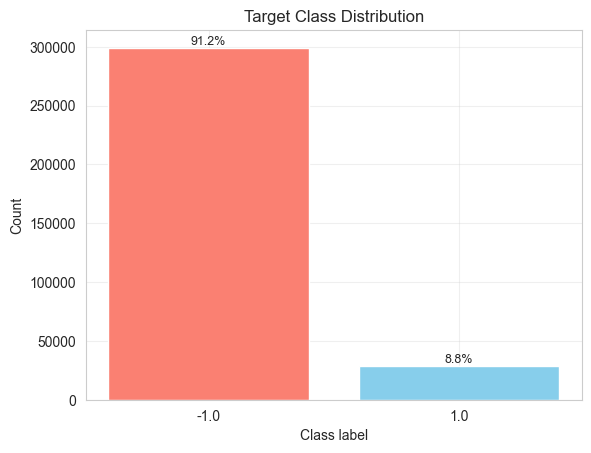

Saved target_summary.json to c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\results\eda\target_summary.json


In [51]:
classes, counts = np.unique(y_train, return_counts=True)
total = np.sum(counts)
percentages = counts / total * 100

print("Target distribution summary:")
print("-" * 40)
for c, n, p in zip(classes, counts, percentages):
    print(f"Class {int(c):>3}: {n:>8} samples ({p:5.2f}%)")
print("-" * 40)
print(f"Total samples: {total}\n")

# plot class balance
plt.bar(classes.astype(str), counts, color=["salmon", "skyblue"])
plt.title("Target Class Distribution")
plt.xlabel("Class label")
plt.ylabel("Count")
for i, (n, p) in enumerate(zip(counts, percentages)):
    plt.text(i, n, f"{p:.1f}%", ha="center", va="bottom", fontsize=9)
plt.grid(alpha=0.3)
plt.show()

# save
target_summary = {
    "total_samples": int(total),
    "class_counts": {int(c): int(n) for c, n in zip(classes, counts)},
    "class_percentages": {int(c): float(p) for c, p in zip(classes, percentages)},
}
save_json(target_summary, "target_summary")

The dataset is highly imbalanced, with the majority class representing over 90% of the samples.  
This imbalance will need to be addressed in the next stages, either through **resampling techniques** or by using **models that account for class imbalance**, such as weighted logistic regression.

# 2. Univariate statistics

### Histograms + Boxplots for all features

We automatically generate all plots in batch for every feature in the dataset. To keep the notebook concise, only the first 5 features are displayed inline - the full set of visualizations can be inspected in the corresponding output folders.

For each feature, we generate :
- **Combined histograms** (relative and absolute frequencies by class, as well as overall KDE)
- **Boxplots**

In [71]:
hist_dir_single = os.path.join(plots_dir, "histograms", "single-features")
hist_dir_target = os.path.join(plots_dir, "histograms", "target-feature")
hist_combined_dir = os.path.join(plots_dir, "histograms", "combined")
box_dir_single = os.path.join(plots_dir, "boxplots", "single-features")

os.makedirs(box_dir_single, exist_ok=True)
os.makedirs(hist_dir_single, exist_ok=True)
os.makedirs(hist_dir_target, exist_ok=True)
os.makedirs(hist_combined_dir, exist_ok=True)

print(f"Histograms (single features): {hist_dir_single}")
print(f"Histograms (feature vs target): {hist_dir_target}")
print(f"Boxplots (single features): {box_dir_single}")

Histograms (single features): C:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\histograms\single-features
Histograms (feature vs target): C:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\histograms\target-feature
Boxplots (single features): C:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\boxplots\single-features


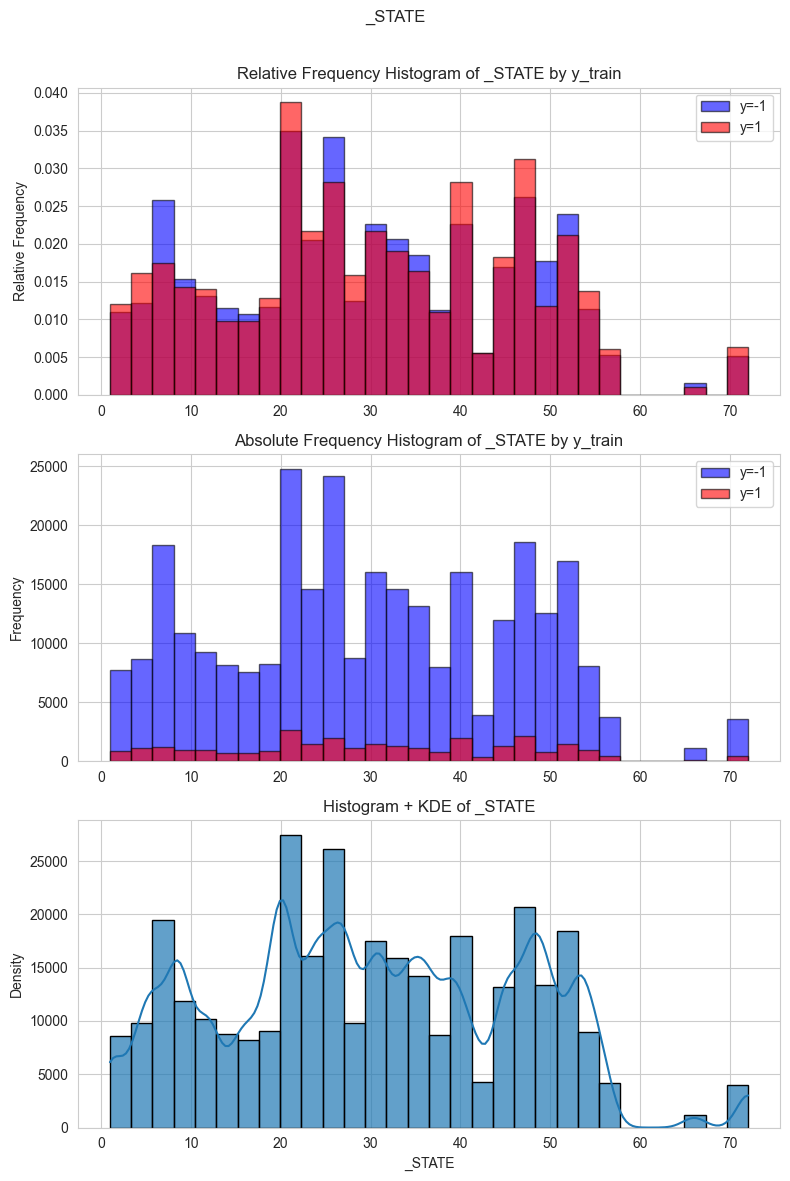

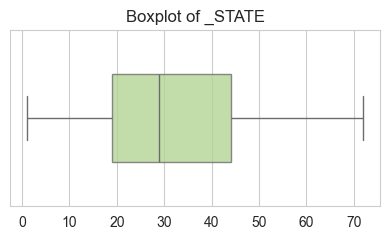

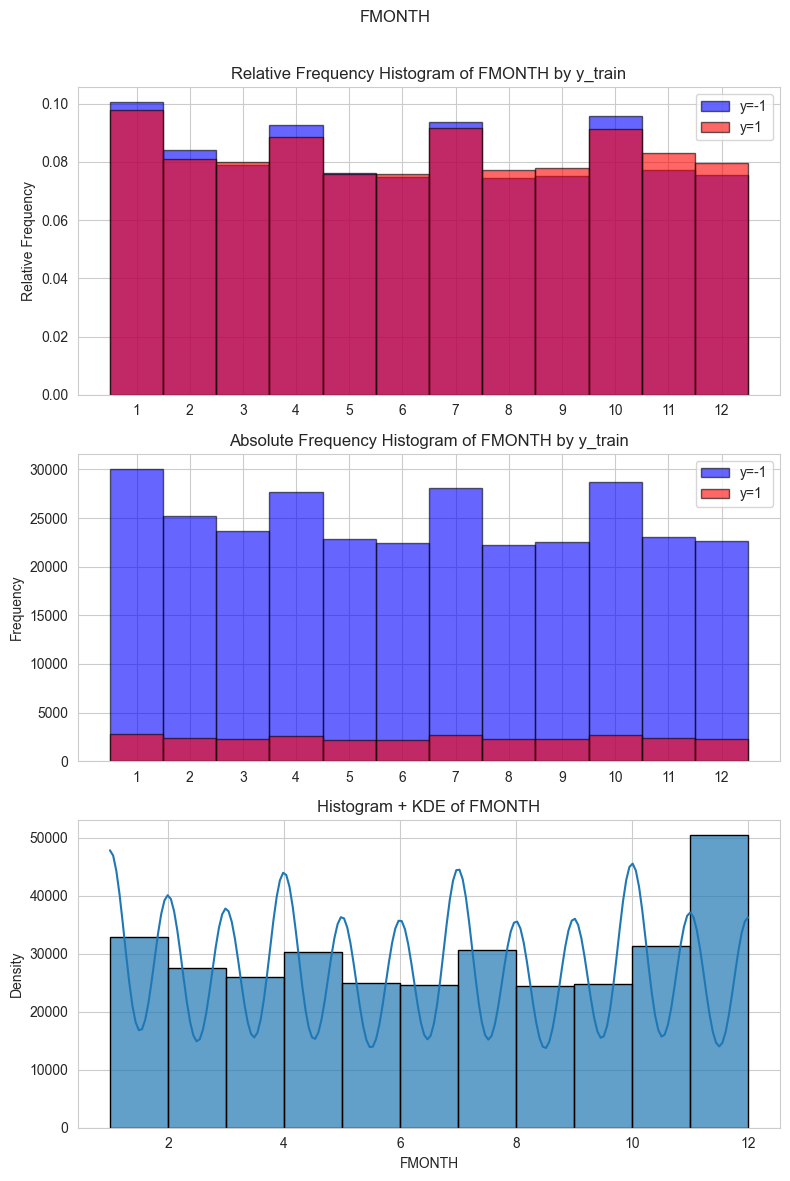

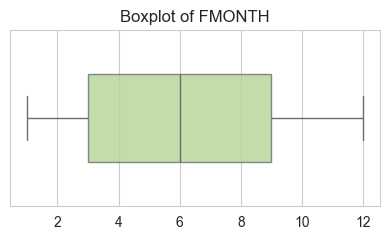

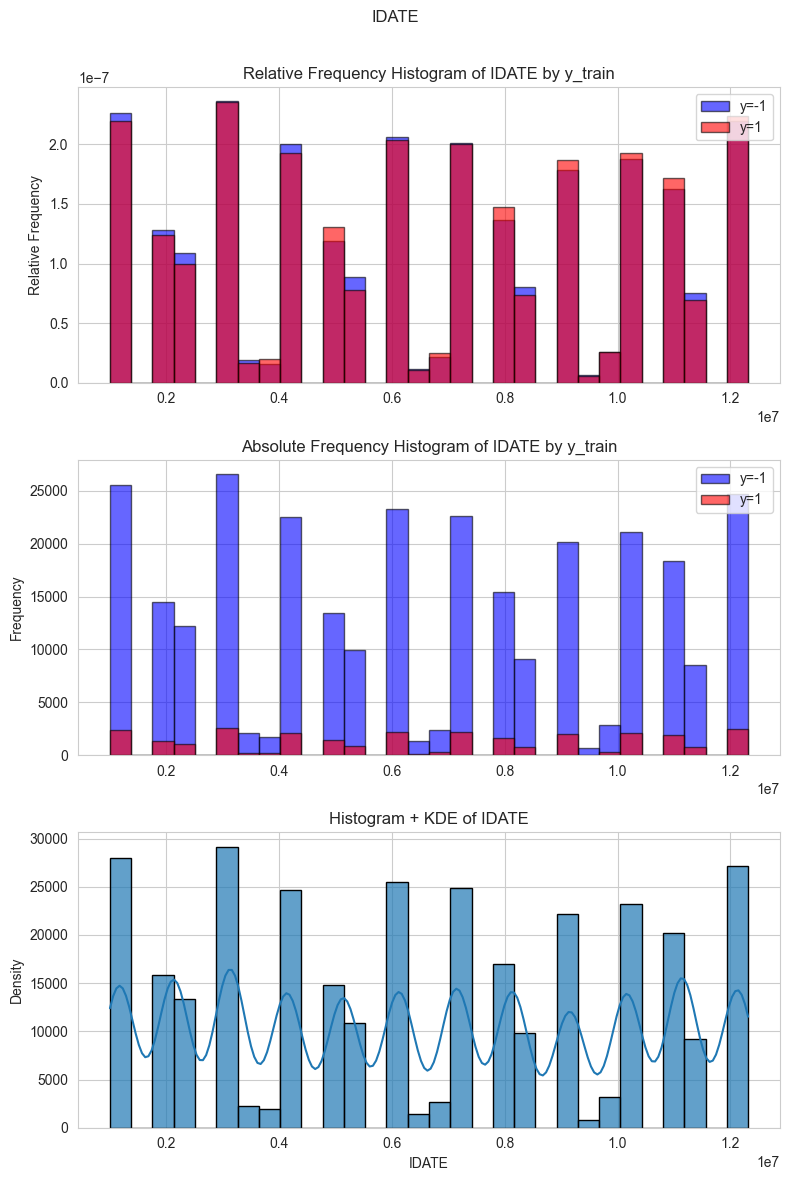

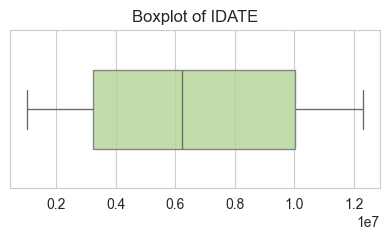

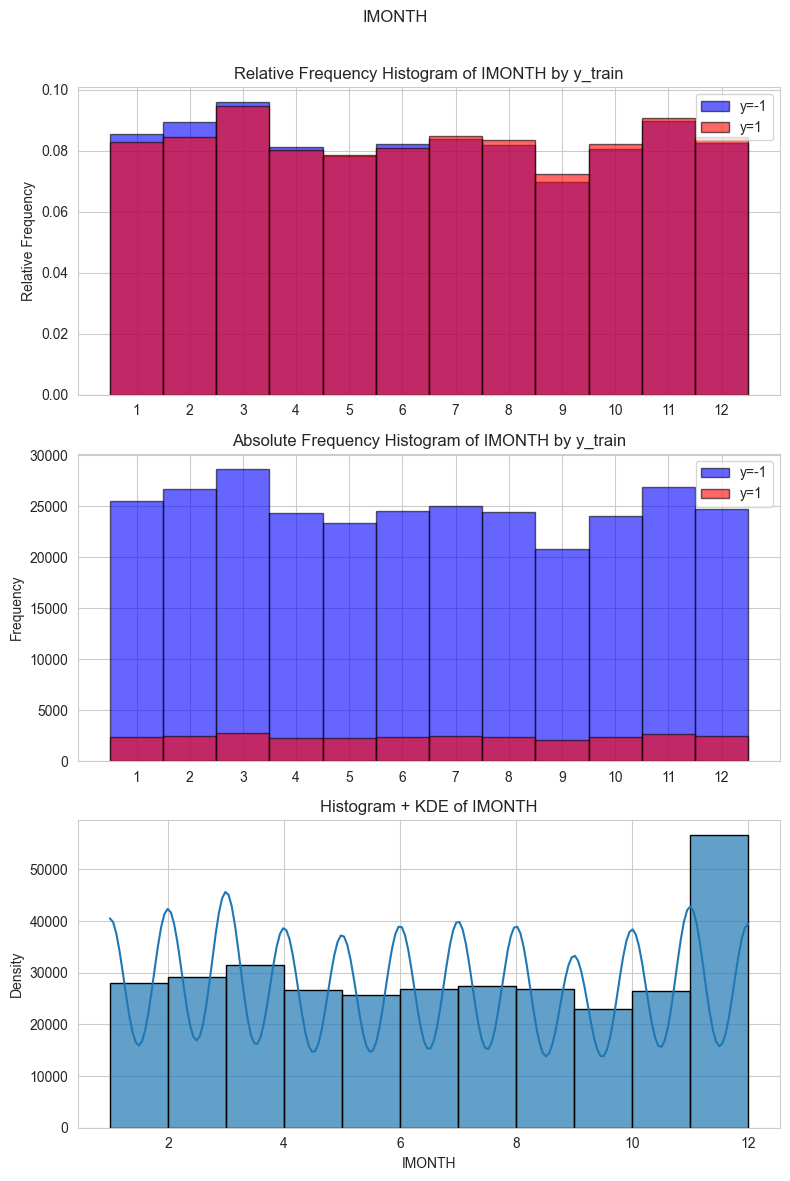

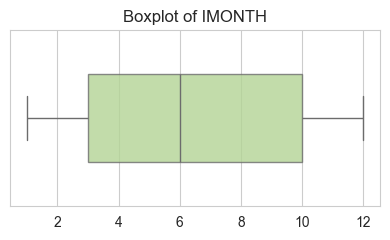

C:\Users\emmaa\AppData\Local\Temp\ipykernel_25016\1038983237.py:34: RuntimeWarning: invalid value encountered in scalar divide
  axes[0].bar(val, np.sum(d_neg == val) / len(d_neg),


Saved combined hist + boxplots for 322 features


In [ ]:
n_features = x_train.shape[1]
n_show = 5
idx_to_name = {v: k for k, v in x_indices.items()} # reverse mapping id to name

for i in range(n_features):
    if i not in idx_to_name:
        continue
    name = idx_to_name[i]
    x = x_train[:, i]
    if np.all(np.isnan(x)):
        continue

    mask = ~np.isnan(x)
    x_valid = x[mask]
    y_valid = y_train[mask]

    if np.nanstd(x_valid) == 0 or len(x_valid) < 2:
        continue

    uniq = np.unique(x_valid)
    is_cat = (len(uniq) <= 20) and np.all(np.equal(np.mod(uniq, 1), 0))

    fig, axes = plt.subplots(3, 1, figsize=(8, 12))
    fig.suptitle(f"{name}", fontsize=12, y=0.98)

    mask_neg = y_valid == -1
    mask_pos = y_valid == 1
    d_neg, d_pos = x_valid[mask_neg], x_valid[mask_pos]

    # relative frequency
    if is_cat:
        bins = np.unique(np.concatenate([d_neg, d_pos]))
        for val in bins:
            axes[0].bar(val, np.sum(d_neg == val) / len(d_neg),
                        width=1, color="blue", alpha=0.6, edgecolor="black",
                        label="y=-1" if val == bins[0] else "")
            axes[0].bar(val, np.sum(d_pos == val) / len(d_pos),
                        width=1, color="red", alpha=0.6, edgecolor="black",
                        label="y=1" if val == bins[0] else "")
        axes[0].set_xticks(bins)
    else:
        bins = 30
        axes[0].hist(d_neg, bins=bins, density=True, alpha=0.6,
                     color="blue", label="y=-1", edgecolor="black")
        axes[0].hist(d_pos, bins=bins, density=True, alpha=0.6,
                     color="red", label="y=1", edgecolor="black")
    axes[0].set_title(f"Relative Frequency Histogram of {name} by y_train")
    axes[0].set_ylabel("Relative Frequency")
    axes[0].legend()

    # absolute freq
    if is_cat:
        for val in bins: # type: ignore
            axes[1].bar(val, np.sum(d_neg == val),
                        width=1, color="blue", alpha=0.6, edgecolor="black",
                        label="y=-1" if val == bins[0] else "") # type: ignore
            axes[1].bar(val, np.sum(d_pos == val),
                        width=1, color="red", alpha=0.6, edgecolor="black",
                        label="y=1" if val == bins[0] else "") # type: ignore
        axes[1].set_xticks(bins)
    else:
        axes[1].hist(d_neg, bins=bins, density=False, alpha=0.6,
                     color="blue", label="y=-1", edgecolor="black")
        axes[1].hist(d_pos, bins=bins, density=False, alpha=0.6,
                     color="red", label="y=1", edgecolor="black")
    axes[1].set_title(f"Absolute Frequency Histogram of {name} by y_train")
    axes[1].set_ylabel("Frequency")
    axes[1].legend()

    # kde 
    sns.histplot(x_valid, bins=bins, kde=True, color="#1f78b4",
                 alpha=0.7, edgecolor="black", ax=axes[2])
    axes[2].set_title(f"Histogram + KDE of {name}")
    axes[2].set_xlabel(name)
    axes[2].set_ylabel("Density")

    plt.tight_layout(rect=[0, 0, 1, 0.97]) # type: ignore
    save_path = os.path.join(hist_combined_dir, f"{name}_hist_combined.png")
    plt.savefig(save_path, bbox_inches="tight")
    if i < n_show:
        plt.show()
    else:
        plt.close()

    # boxplot
    plt.figure(figsize=(4, 2.5))
    sns.boxplot(x=x_valid, color="#b2df8a", width=0.5, boxprops=dict(alpha=0.8))
    plt.title(f"Boxplot of {name}")
    plt.tight_layout()
    plt.savefig(os.path.join(box_dir_single, f"{name}_box.png"), bbox_inches="tight")
    if i < n_show:
        plt.show()
    else:
        plt.close()

print(f"Saved combined hist + boxplots for {x_train.shape[1]} features")

Based on the previous exploratory analysis, we manually select a subset of features that show meaningful variation or relevance to the target variable. We also classify them as continuous or categorical to guide the next set ot visualizations.

In [68]:
interesting_columns = ["GENHLTH", "PHYSHLTH", "MENTHLTH", "POORHLTH", "HLTHPLN1", "MEDCOST", "CHECKUP1",
                        "BPHIGH4", "SEX", "WEIGHT2", "HEIGHT3", "QLACTLM2", 
                        "DIFFWALK", "SMOKE100", "SMOKDAY2", "EXERANY2", "EXRACT11",
                        "HLTHPLN1", "TOLDHI2", "CHCCOPD1", "CHCKIDNY",
                        "CHCOCNCR", "CIMEMLOS", "DIABETE3", "EDUCA", "EMPLOY1", 
                        "WTCHSALT", "HAREHAB1",  "SCNTMNY1", "VETERAN3", "INCOME2",
                        "_LTASTH1", "_RACE", "_AGE80", "_BMI5"
                        ]

In [ ]:
# divide features in x_train_clean into continuous and categorical
continuous_features = []
categorical_features = []

for idx, feature_name in enumerate(interesting_columns):
    name = feature_name
    col = x_data[:, idx]
    unique_vals = np.unique(col[~np.isnan(col)])
    # heuristic: categorical if <= 10 unique values and all are integers
    if len(unique_vals) <= 20 and np.all(np.equal(np.mod(unique_vals, 1), 0)):
        categorical_features.append(name)
    else:
        continuous_features.append(name)

print("Continuous features:", continuous_features)
print("Categorical features:", categorical_features)

Continuous features: ['GENHLTH', 'PHYSHLTH', 'POORHLTH', 'MEDCOST', 'SEX', 'WEIGHT2', 'WTCHSALT', 'SCNTMNY1', 'VETERAN3', 'INCOME2']
Categorical features: ['MENTHLTH', 'HLTHPLN1', 'CHECKUP1', 'BPHIGH4', 'HEIGHT3', 'QLACTLM2', 'DIFFWALK', 'SMOKE100', 'SMOKDAY2', 'EXERANY2', 'EXRACT11', 'HLTHPLN1', 'TOLDHI2', 'CHCCOPD1', 'CHCKIDNY', 'CHCOCNCR', 'CIMEMLOS', 'DIABETE3', 'EDUCA', 'EMPLOY1', 'HAREHAB1', '_LTASTH1', '_RACE', '_AGE80', '_BMI5']


## Feature statistics table 
We now create a table of descriptive statistics only for the selected columns, in order to further analyze them.

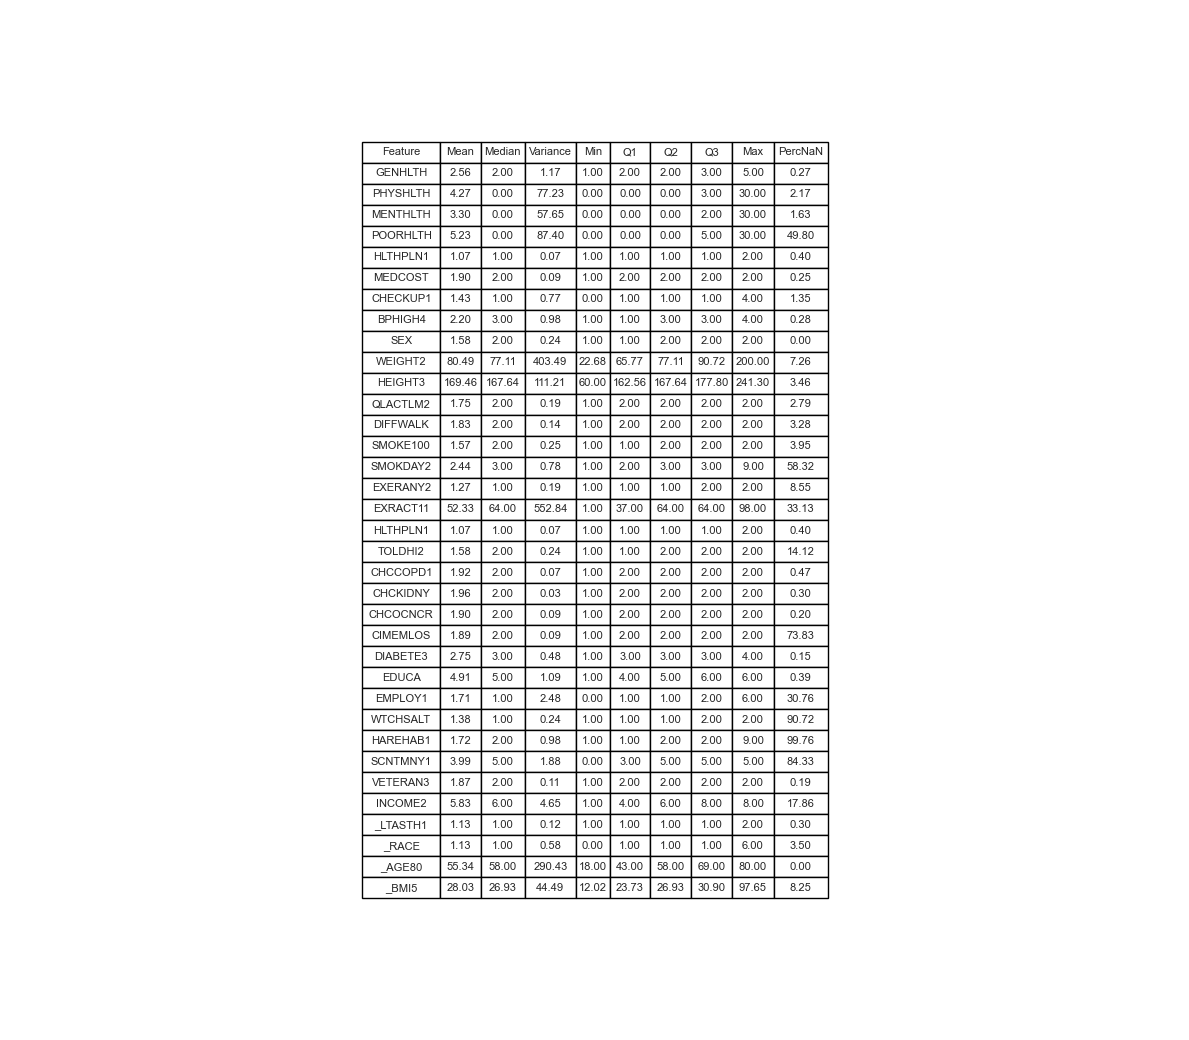

Feature statistics saved to C:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\results\eda\feature_stats.csv


In [69]:
# Feature statistics
fs_dir = os.path.join(plots_dir, "feature_stats")
os.makedirs(fs_dir, exist_ok=True)

stats = []
skipped = []

for name in interesting_columns:
    if name not in x_indices:
        skipped.append(name)
        continue

    idx = x_indices[name]
    if idx >= x_train.shape[1]:
        skipped.append(name)
        continue

    col = x_train[:, idx].astype(float)
    n_total = col.shape[0]
    mask_notnan = ~np.isnan(col)
    col_nonan = col[mask_notnan]
    perc_nan = 100 * (n_total - col_nonan.size) / n_total

    if col_nonan.size == 0:
        stats.append([name] + [np.nan] * 8 + [perc_nan])
        continue

    # compute descriptive statistics
    mean = np.mean(col_nonan)
    median = np.median(col_nonan)
    var = np.var(col_nonan)
    q0 = np.percentile(col_nonan, 0)
    q1 = np.percentile(col_nonan, 25)
    q2 = np.percentile(col_nonan, 50)
    q3 = np.percentile(col_nonan, 75)
    q100 = np.percentile(col_nonan, 100)

    stats.append([name, mean, median, var, q0, q1, q2, q3, q100, perc_nan])

# saving
csv_path = os.path.join(save_dir, "feature_stats.csv")
header = ["Feature", "Mean", "Median", "Variance", "Min", "Q1", "Q2", "Q3", "Max", "PercNaN"]

with open(csv_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(header)
    writer.writerows(stats)

fig, ax = plt.subplots(figsize=(12, len(stats) * 0.3))
ax.axis("off")
table = ax.table(
    cellText=[[f"{v:.2f}" if isinstance(v, float) else v for v in row] for row in stats],
    colLabels=header,
    loc="center",
    cellLoc="center"
)
table.auto_set_font_size(False)
table.set_fontsize(8)
table.auto_set_column_width(col=list(range(len(header))))
plt.tight_layout()
plt.savefig(os.path.join(fs_dir, "feature_stats.png"), bbox_inches="tight")
plt.show()

print(f"Feature statistics saved to {csv_path}")
if skipped:
    print(f"Skipped {len(skipped)} columns not found in x_indices:")
    print(", ".join(skipped))


# 3. Bi- and multi-variate statistics
In this section, we explore relationships between features to detect potential dependencies or redundancies. 


We first visualize scatterplots between continuous features to spot linear or nonlinear trends, class separations, or clusters. Then, we compute and plot the full pairwise correlation matrix to quantify how strongly features are related, highlighting only correlations with absolute value greater than 0.05.

## Scatterplots
We visualize pairwise relationships between the selected continuous features using scatterplots. This helps reveal potential correlations, clusters, or separations between classes that may not be evident from univariate analysis. Again, the plots are not shown inline in order not to clutter the notebook.

In [ ]:
# scatterplots for continuous feature pairs
scatter_dir = os.path.join(plots_dir, "scatterplots")
os.makedirs(scatter_dir, exist_ok=True)

# parameters
features_per_group = 4
if "continuous_features" in locals():
    continuous_subgroups = [
        continuous_features[i:i + features_per_group]
        for i in range(0, len(continuous_features), features_per_group)
    ]
else:
    continuous_subgroups = [feature_names[i:i + features_per_group]
                            for i in range(0, len(feature_names), features_per_group)]

for g_idx, subgroup in enumerate(continuous_subgroups):
    num_feats = len(subgroup)
    if num_feats < 2:
        continue

    n_pairs = num_feats * (num_feats - 1) // 2
    n_cols = min(3, n_pairs)
    n_rows = int(np.ceil(n_pairs / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
    axes = np.array(axes).reshape(-1)

    pair_idx = 0
    for i in range(num_feats):
        for j in range(i + 1, num_feats):
            f1, f2 = subgroup[i], subgroup[j]
            idx1, idx2 = x_indices[f1], x_indices[f2]

            x1 = x_train[:, idx1]
            x2 = x_train[:, idx2]
            mask = ~np.isnan(x1) & ~np.isnan(x2)
            x1_clean, x2_clean = x1[mask], x2[mask]
            y_clean = y_train[mask]

            ax = axes[pair_idx]
            ax.scatter(x1_clean[y_clean == -1], x2_clean[y_clean == -1],
                       c="#1f78b4", alpha=0.5, s=15, label="y = -1")
            ax.scatter(x1_clean[y_clean == 1], x2_clean[y_clean == 1],
                       c="#e31a1c", alpha=0.5, s=15, label="y = 1")
            ax.set_xlabel(f1)
            ax.set_ylabel(f2)
            ax.set_title(f"{f1} vs {f2}")
            ax.legend(fontsize=8)
            pair_idx += 1

    for k in range(pair_idx, len(axes)):
        axes[k].axis("off")

    plt.tight_layout()
    fname = f"group{g_idx+1}_scatter.png"
    plt.savefig(os.path.join(scatter_dir, fname), bbox_inches="tight", dpi=200)
    plt.close()

print(f"Scatterplots saved in {scatter_dir}")

Scatterplots saved in C:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\scatterplots


## Correlations

In [ ]:
# correlation matrix
corr_dir = os.path.join(plots_dir, "heatmaps")
os.makedirs(corr_dir, exist_ok=True)

# init matrix with nans
corr_matrix = np.full((x_train.shape[1], x_train.shape[1]), np.nan)

# compute pairwise correlations
for i in range(x_train.shape[1]):
    for j in range(x_train.shape[1]):
        col_i = x_train[:, i]
        col_j = x_train[:, j]
        mask = ~np.isnan(col_i) & ~np.isnan(col_j)
        if np.sum(mask) > 1:
            std_i = np.std(col_i[mask])
            std_j = np.std(col_j[mask])
            if std_i == 0 or std_j == 0:
                corr_matrix[i, j] = np.nan
            else:
                corr_matrix[i, j] = np.corrcoef(col_i[mask], col_j[mask])[0, 1]

# set diagonal to 1
np.fill_diagonal(corr_matrix, 1.0)

# keep only non-negligible correlations
threshold = 0.05
marked_corr = np.where(np.abs(corr_matrix) > threshold, corr_matrix, np.nan)

# plot and save
plt.figure(figsize=(14, 12))
im = plt.imshow(marked_corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.title(f"correlation matrix (|corr| > {threshold} marked)")
plt.xticks(range(len(feature_names)), feature_names, fontsize=6)
plt.yticks(range(len(feature_names)), feature_names, fontsize=6)
plt.tight_layout()
plt.savefig(os.path.join(corr_dir, f"correlation_matrix_marked_{threshold}.png"), bbox_inches="tight")
plt.close()

print(f"Saved correlation matrix heatmap to {corr_dir}")

Saved correlation matrix heatmap to C:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\heatmaps
